<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Count reports separately from repeated indicators

**Does an indicator repeated in a paragraph have more support than one appearing in two reports?**
We will extract typed candidates from six synthetic report rows, retain missing and
empty input states, and build a shortlist using distinct report coverage. We will
also inspect a known false-positive case in the pinned release.

All report text is invented. Domain names use `.test`, IP examples include documentation
and private ranges, and the CVE-shaped token is illustrative, not a verified advisory.
Recognition is not evidence of compromise, maliciousness, source independence or
accuracy. The worker only processes text; it performs no DNS, URL or reputation lookup.

## Choose the minimum number of reports

`MIN_REPORTS=1` includes every extracted typed candidate. The experiment changes it
to `2`. This is a transparent shortlist policy based on the supplied rows, not a
confidence or risk score. Repeated mentions inside a report do not increase support:
the extractors deduplicate their results within each input.

In [1]:
MIN_REPORTS = 1

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(MIN_REPORTS) is not int or not 1 <= MIN_REPORTS <= 6:
    raise ValueError("MIN_REPORTS must be an integer from 1 to 6.")
type_counts = support = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ioc/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ioc/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ioc/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ioc/notebooks/pyproject.toml.

## Attach the native release and inspect its type registry

The literal `github-auto` location fetches the platform's v0.4.0 binary, verifies
the release checksum and uses the extension's cache. No Rust installation or local
worker build is needed. The registry provides type labels and groupings for later SQL.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ioc' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-ioc@v0.4.0');
SELECT name,kind,extractor FROM ioc.main.ioc_types ORDER BY kind,name;

,name,kind,extractor
0,email,email,extract_emails
1,md5,hash,extract_hashes
2,sha1,hash,extract_hashes
3,sha256,hash,extract_hashes
4,sha512,hash,extract_hashes
5,domain,network,extract_domains
6,ipv4,network,extract_ipv4
7,ipv6,network,extract_ipv6
8,url,network,extract_urls
9,cve,vulnerability,extract_cves


## Preserve the report population before expanding lists

The first report mentions the same IPv4 address twice, once defanged and once in
ordinary form. Extractors refang a copy before matching, so those spellings collapse
to one value in that report. R4 has nonempty text with no matches, R5 is an empty
string, and R6 is SQL NULL. None of those states establishes whether a source is benign.

The worker scans at most 4 MiB per input. These tiny fixtures are checked below to be
well within that limit; the notebook makes no completeness claim for longer inputs.

In [4]:
%%sql
CREATE TABLE reports(report_id VARCHAR,report_text VARCHAR);
INSERT INTO reports VALUES
 ('R1','Synthetic report: hxxps://updates[.]example[.]test/payload from 192[.]0[.]2[.]10. Repeat 192.0.2.10. Contact ops[at]example[.]test. Hash d41d8cd98f00b204e9800998ecf8427e and CVE-2026-12345.'),
 ('R2','Synthetic follow-up: https://updates.example.test/payload from 192.0.2.10 with review.example.test and CVE-2026-12345.'),
 ('R3','Synthetic note: review[.]example[.]test with 2001:db8::1 and 10.0.0.1. Hash d41d8cd98f00b204e9800998ecf8427e.'),
 ('R4','Nothing machine readable in this note.'),
 ('R5',''),
 ('R6',NULL);
CREATE TABLE extracted_lists AS
 SELECT *,octet_length(encode(report_text)) AS input_bytes,
        ioc.main.is_ioc(report_text) AS has_candidate,
        ioc.main.extract_ipv4(report_text) AS ipv4,
        ioc.main.extract_ipv6(report_text) AS ipv6,
        ioc.main.extract_urls(report_text) AS urls,
        ioc.main.extract_emails(report_text) AS emails,
        ioc.main.extract_domains(report_text) AS domains,
        ioc.main.extract_hashes(report_text) AS hashes,
        ioc.main.extract_cves(report_text) AS cves
 FROM reports;
SELECT report_id,input_bytes,has_candidate,ipv4,domains FROM extracted_lists ORDER BY report_id;

,report_id,input_bytes,has_candidate,ipv4,domains
0,R1,189,True,[192.0.2.10],[]
1,R2,118,True,[192.0.2.10],[review.example.test]
2,R3,109,True,[10.0.0.1],[review.example.test]
3,R4,38,False,[],[]
4,R5,0,False,[],[]
5,R6,<NA>,<NA>,<NA>,<NA>


## Convert typed lists to report–indicator rows

Use scalar extractors for a report column, then unnest their materialized lists.
The `extract_iocs` table function is convenient for a constant text argument; we
use it later for a focused release check. Hash candidates are labeled by their
recognized hexadecimal form with `hash_type`, without asserting anything about file content.

The grain below is **one report, type and returned value**. A host claimed by a URL
or email is not also reported as a bare domain in that same input. We keep the worker's
returned values and types, rather than merging unrelated types into one string key.

In [5]:
%%sql
CREATE TABLE candidates AS
 SELECT report_id,'ipv4' AS type,unnest(ipv4) AS value FROM extracted_lists
 UNION ALL SELECT report_id,'ipv6',unnest(ipv6) FROM extracted_lists
 UNION ALL SELECT report_id,'url',unnest(urls) FROM extracted_lists
 UNION ALL SELECT report_id,'email',unnest(emails) FROM extracted_lists
 UNION ALL SELECT report_id,'domain',unnest(domains) FROM extracted_lists
 UNION ALL SELECT report_id,ioc.main.hash_type(value),value
   FROM (SELECT report_id,unnest(hashes) AS value FROM extracted_lists)
 UNION ALL SELECT report_id,'cve',unnest(cves) FROM extracted_lists;
SELECT c.report_id,t.kind,c.type,ioc.main.defang(c.value) AS display_value
FROM candidates c JOIN ioc.main.ioc_types t ON c.type=t.name ORDER BY c.report_id,c.type,c.value;

,report_id,kind,type,display_value
0,R1,vulnerability,cve,CVE-2026-12345
1,R1,email,email,ops[at]example[.]test
2,R1,network,ipv4,192[.]0[.]2[.]10
3,R1,hash,md5,d41d8cd98f00b204e9800998ecf8427e
4,R1,network,url,hxxps[://]updates[.]example[.]test/payload
5,R2,vulnerability,cve,CVE-2026-12345
6,R2,network,domain,review[.]example[.]test
7,R2,network,ipv4,192[.]0[.]2[.]10
8,R2,network,url,hxxps[://]updates[.]example[.]test/payload
9,R3,network,domain,review[.]example[.]test


## Keep no-match, empty and missing inputs distinct

Unnesting a NULL or empty list emits no rows. A left join to the original report
population restores all six inputs. Known text with no candidates gets a count of
zero; missing text retains a NULL count. The display form is defanged for presentation,
but aggregation continues to use the full typed values.

In [6]:
%%sql
CREATE TABLE report_audit AS
 SELECT r.report_id,r.report_text,
 CASE WHEN r.report_text IS NULL THEN 'Missing text'
      WHEN r.report_text='' THEN 'Empty text'
      WHEN c.candidates IS NULL THEN 'Text with no matches'
      ELSE 'Text with candidates' END AS input_state,
 CASE WHEN r.report_text IS NOT NULL THEN coalesce(c.candidates,0) END AS candidate_count
 FROM reports r LEFT JOIN (SELECT report_id,count(*) AS candidates FROM candidates GROUP BY report_id) c USING(report_id);
SELECT report_id,input_state,candidate_count FROM report_audit ORDER BY report_id;

,report_id,input_state,candidate_count
0,R1,Text with candidates,5
1,R2,Text with candidates,4
2,R3,Text with candidates,4
3,R4,Text with no matches,0
4,R5,Empty text,0
5,R6,Missing text,<NA>


## Separate report–indicator pairs from distinct indicators

The same typed value in two reports contributes two rows to the first measure but
one to the second. Neither measure is a count of all raw mentions. This audit stays
fixed while the shortlist threshold changes.

In [7]:
%%sql type_counts <<
SELECT c.type,t.kind,count(*) AS report_indicator_pairs,count(DISTINCT value) AS distinct_indicators
FROM candidates c JOIN ioc.main.ioc_types t ON c.type=t.name
GROUP BY c.type,t.kind ORDER BY report_indicator_pairs DESC,c.type;

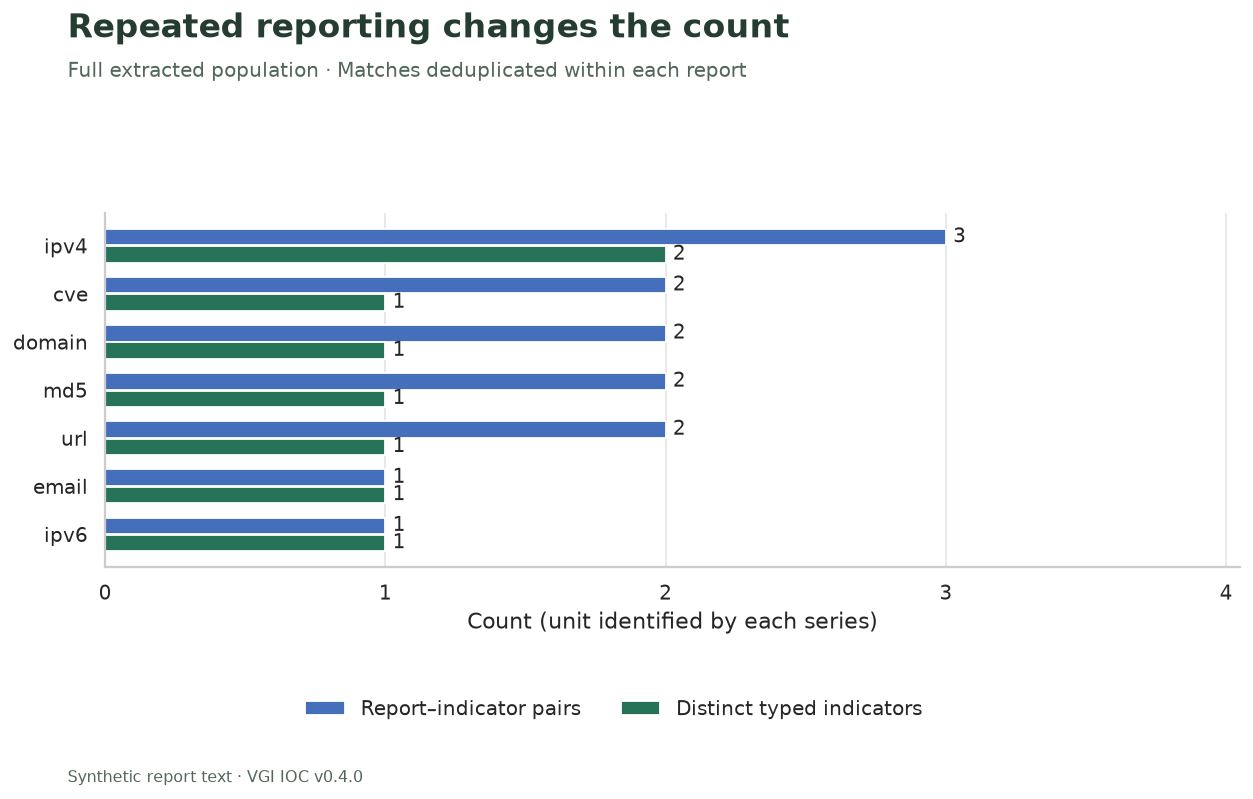

The six input rows yield **13 report–indicator pairs** and **8 distinct typed indicators**. R1's repeated IPv4 mention still contributes one row for that address. These are extraction counts, not incident or threat counts.

In [8]:
fig, ax = plt.subplots(figsize=(10, 6.2))
y = np.arange(len(type_counts))
for offset, column, color, label in [
    (-0.18, "report_indicator_pairs", "#456fba", "Report–indicator pairs"),
    (0.18, "distinct_indicators", "#267358", "Distinct typed indicators"),
]:
    bars = ax.barh(y + offset, type_counts[column], height=0.34, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=11)
ax.set_yticks(y, type_counts.type)
ax.invert_yaxis()
ax.set_xlim(0, max(type_counts.report_indicator_pairs.max(), 1) * 1.35)
ax.set_xlabel("Count (unit identified by each series)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Repeated reporting changes the count",
    "Full extracted population · Matches deduplicated within each report",
    "01_pair_and_indicator_counts.png",
    bottom=0.18,
)
prose(
    f"The six input rows yield **{int(type_counts.report_indicator_pairs.sum())} report–indicator pairs** "
    f"and **{int(type_counts.distinct_indicators.sum())} distinct typed indicators**. "
    "R1's repeated IPv4 mention still contributes one row for that address. "
    "These are extraction counts, not incident or threat counts."
)

## Build the shortlist from distinct report coverage

Count distinct report IDs for each full `(type, value)` key. Keep the report list
with the candidate so the selection is inspectable. The threshold is local and
does not establish independence between the authored report rows.

In [9]:
%%sql support <<
SELECT type,value,ioc.main.defang(value) AS display_value,
       count(DISTINCT report_id) AS reports,
       string_agg(DISTINCT report_id,', ' ORDER BY report_id) AS report_ids,
       count(DISTINCT report_id)>={{ MIN_REPORTS }} AS selected
FROM candidates GROUP BY type,value ORDER BY reports DESC,type,value;

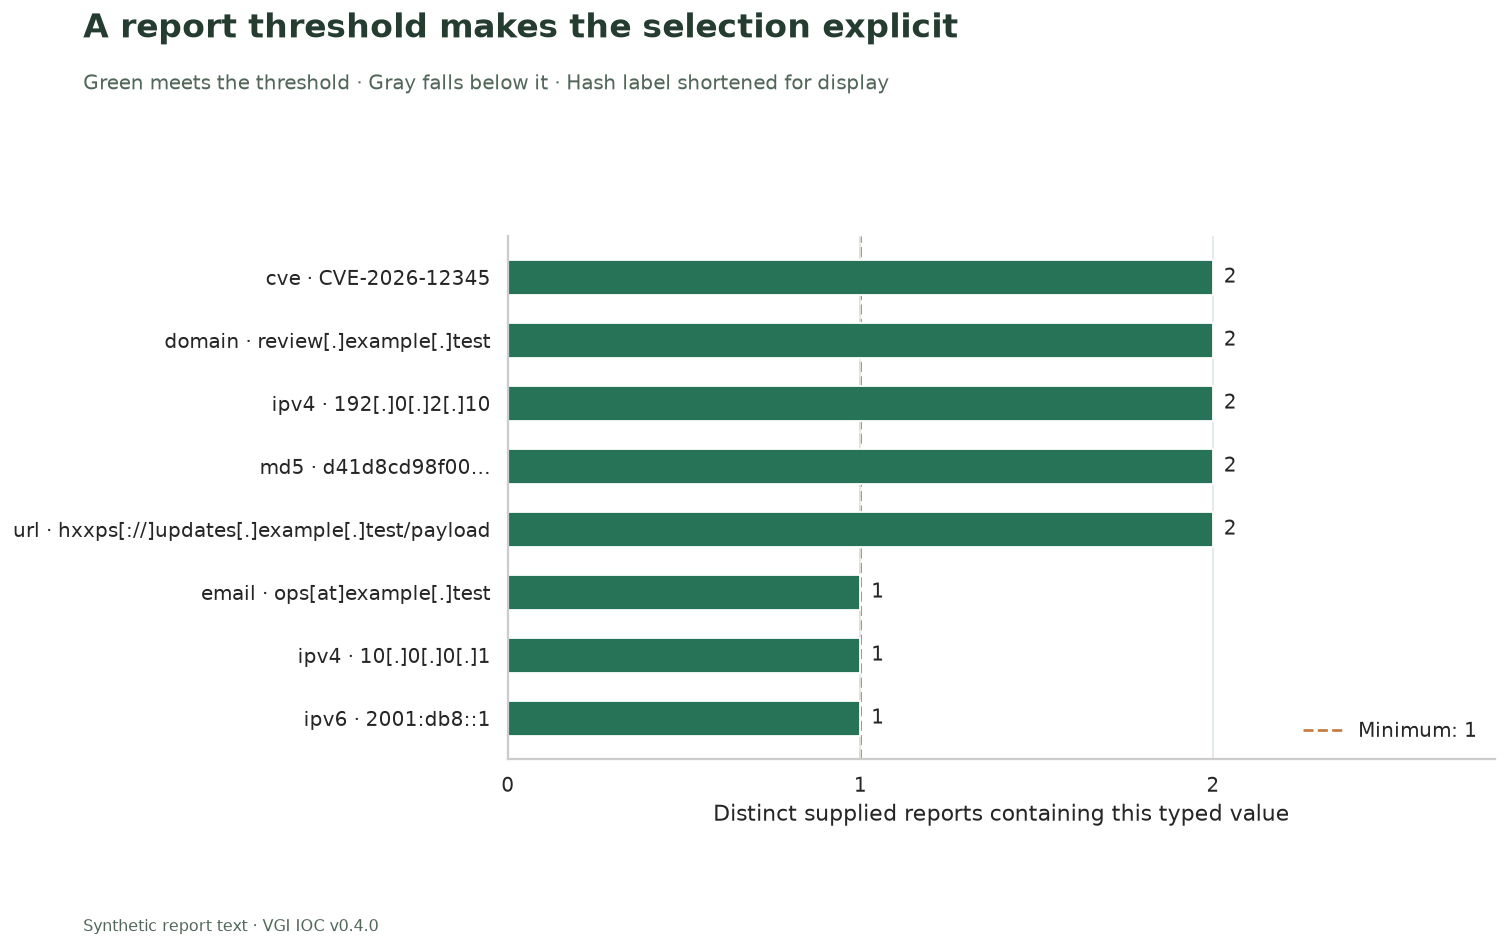

At a minimum of **1 report(s)**, **8 of 8 typed candidates** meet the shortlist rule. The text, extracted values and support counts are unchanged. A higher count is not a substitute for validating context, provenance or meaning.

,type,display_value,reports,report_ids
0,cve,CVE-2026-12345,2,"R1, R2"
1,domain,review[.]example[.]test,2,"R2, R3"
2,ipv4,192[.]0[.]2[.]10,2,"R1, R2"
3,md5,d41d8cd98f00b204e9800998ecf8427e,2,"R1, R3"
4,url,hxxps[://]updates[.]example[.]test/payload,2,"R1, R2"
5,email,ops[at]example[.]test,1,R1
6,ipv4,10[.]0[.]0[.]1,1,R3
7,ipv6,2001:db8::1,1,R3


In [10]:
fig, ax = plt.subplots(figsize=(12, 7.4))
labels = [
    f"{r.type} · {r.display_value if r.type != 'md5' else r.display_value[:12] + '…'}"
    for r in support.itertuples()
]
colors = ["#267358" if ok else "#a8b2ac" for ok in support.selected]
bars = ax.barh(labels, support.reports, color=colors, height=0.55)
ax.bar_label(bars, padding=6, fontsize=11)
ax.axvline(MIN_REPORTS, color="#c57b40", ls="--", lw=1.5, label=f"Minimum: {MIN_REPORTS}", zorder=0)
ax.invert_yaxis()
ax.set_xlim(0, max(int(support.reports.max()), MIN_REPORTS) + 0.8)
ax.set_xlabel("Distinct supplied reports containing this typed value")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
finish(
    fig,
    "A report threshold makes the selection explicit",
    "Green meets the threshold · Gray falls below it · Hash label shortened for display",
    "02_report_coverage.png",
    bottom=0.11,
)
selected = int(support.selected.sum())
prose(
    f"At a minimum of **{MIN_REPORTS} report(s)**, **{selected} of {len(support)} typed candidates** "
    "meet the shortlist rule. The text, extracted values and support counts are unchanged. "
    "A higher count is not a substitute for validating context, provenance or meaning."
)
display(support.loc[support.selected, ["type", "display_value", "reports", "report_ids"]])

## Inspect a known false-positive case in this pinned release

Here `tool.exe` is a URL-path token and `first.last` is an email local part.
The v0.4.0 release also emits them as domain candidates. This is an observed release
limitation: the repository's later source contains a fix, but this notebook uses the
published native release named in its connection.

The focused case is separate from the report population above. It illustrates why
recognizable syntax must not be relabeled as verified threat intelligence. Defanging
changes display syntax; it does not validate an indicator or its context.

In [11]:
%%sql
CREATE TABLE release_case AS
 SELECT * FROM ioc.main.extract_iocs('https://updates.example.test/tool.exe and first.last@example.test');
SELECT type,value,ioc.main.defang(value) AS display_form,
       CASE WHEN type='domain' AND value IN ('tool.exe','first.last')
            THEN 'False-positive token in this synthetic context' ELSE 'Expected syntactic candidate' END AS interpretation
FROM release_case ORDER BY type,value;

,type,value,display_form,interpretation
0,domain,first.last,first[.]last,False-positive token in this synthetic context
1,domain,tool.exe,tool[.]exe,False-positive token in this synthetic context
2,email,first.last@example.test,first[.]last[at]example[.]test,Expected syntactic candidate
3,url,https://updates.example.test/tool.exe,hxxps[://]updates[.]example[.]test/tool[.]exe,Expected syntactic candidate


## Check identity, list semantics and count reconciliation

The checks audit how the sample is processed. They do not assert that candidate
values identify malicious infrastructure, that the CVE-shaped text is registered,
or that any named file exists. The original reports remain available throughout.

In [12]:
%%sql checks <<
SELECT 'All six unique report IDs survive the population audit' AS invariant,
 (SELECT count(*)=6 AND count(DISTINCT report_id)=6 FROM report_audit) AS passed
UNION ALL SELECT 'Every supplied text is inside the 4 MiB scan bound',
 NOT EXISTS(SELECT 1 FROM extracted_lists WHERE input_bytes>4*1024*1024)
UNION ALL SELECT 'Missing input retains NULL list and scalar results',
 (SELECT ipv4 IS NULL AND ipv6 IS NULL AND urls IS NULL AND emails IS NULL
   AND domains IS NULL AND hashes IS NULL AND cves IS NULL AND has_candidate IS NULL
   FROM extracted_lists WHERE report_id='R6')
UNION ALL SELECT 'Empty and no-match text have empty lists and known zero counts',
 (SELECT bool_and(len(ipv4)=0 AND len(domains)=0 AND NOT has_candidate) FROM extracted_lists WHERE report_id IN ('R4','R5'))
 AND (SELECT bool_and(candidate_count=0) FROM report_audit WHERE report_id IN ('R4','R5'))
UNION ALL SELECT 'Missing input count stays NULL',
 (SELECT candidate_count IS NULL FROM report_audit WHERE report_id='R6')
UNION ALL SELECT 'Extracted report/type/value keys are unique',
 (SELECT count(*)=count(DISTINCT (report_id,type,value)) FROM candidates)
UNION ALL SELECT 'Repeated and defanged IPv4 forms collapse within R1',
 (SELECT count(*)=1 AND min(value)='192.0.2.10' FROM candidates WHERE report_id='R1' AND type='ipv4')
UNION ALL SELECT 'Every extracted type has a registry entry',
 NOT EXISTS(SELECT 1 FROM candidates c LEFT JOIN ioc.main.ioc_types t ON c.type=t.name WHERE t.name IS NULL)
UNION ALL SELECT 'Boolean recognition agrees with nonempty extracted lists',
 NOT EXISTS(SELECT 1 FROM report_audit a JOIN extracted_lists e USING(report_id)
   WHERE a.report_text IS NOT NULL AND e.has_candidate IS DISTINCT FROM (a.candidate_count>0))
UNION ALL SELECT 'Report counts reconcile with typed candidate rows',
 (SELECT sum(candidate_count) FROM report_audit)=(SELECT count(*) FROM candidates)
UNION ALL SELECT 'Display defanging round-trips for these extracted values',
 NOT EXISTS(SELECT 1 FROM candidates WHERE ioc.main.refang(ioc.main.defang(value)) IS DISTINCT FROM value);

In [13]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
assert int(support.reports.sum()) == int(type_counts.report_indicator_pairs.sum())
prose(
    f"**{len(checks)} SQL checks and one coverage reconciliation passed.** "
    "The separate release diagnostic still exposes two false-positive domain tokens."
)

,invariant,passed
0,All six unique report IDs survive the populati...,True
1,Every supplied text is inside the 4 MiB scan b...,True
2,Missing input retains NULL list and scalar res...,True
3,Empty and no-match text have empty lists and k...,True
4,Missing input count stays NULL,True
5,Extracted report/type/value keys are unique,True
6,Repeated and defanged IPv4 forms collapse with...,True
7,Every extracted type has a registry entry,True
8,Boolean recognition agrees with nonempty extra...,True
9,Report counts reconcile with typed candidate rows,True


**11 SQL checks and one coverage reconciliation passed.** The separate release diagnostic still exposes two false-positive domain tokens.

## Experiment: require a second report

Change only `MIN_REPORTS` from `1` to `2`, restart and run all. Predict which
candidates disappear from the shortlist. Confirm that the full-population chart,
input diagnostics and release-specific false-positive case remain unchanged.

For an empty-shortlist boundary, try `4`: no value appears in four supplied reports.
The coverage chart still shows every extracted candidate and the selected table
becomes empty. Restore `1` for the saved default. This is a count-based exploration,
not a threat ranking or an automated blocking policy.

In [14]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)